[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Forma de la distribución.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete · Módulo II: *Describir y comparar*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En este *notebook* se analizará la forma de una distribución (asimetría, curtosis y multimodalidad) con histogramas, KDE, ECDF y diagramas de caja.

## 🧭 Cómo usar este *notebook*.

* Ejecuta las celdas **en orden** (`Shift + Enter`).
* **Ejercicio básico:** lo que todos deben dominar.
* **Reto (opcional):** para quien quiere profundizar. Se puede resolver como práctica.
* Las celdas `# TU CÓDIGO AQUÍ` y *✍️ Tu respuesta* son para ti.

## 📚 Referencia de la API: curso py311.

Este *notebook* usa métodos ya vistos en py311 sin repasarlos uno por uno: `quantile`, `value_counts` y `nlargest` en [py311 · 19 Herramientas de análisis de datos](https://github.com/PythonistaMX/py311/blob/main/19_herramientas_de_analisis_de_datos.ipynb); `transform` y `apply` en [py311 · 17 Los métodos `apply()` y `transform()`](https://github.com/PythonistaMX/py311/blob/main/17_metodos_apply_y_transform.ipynb); `groupby` en [py311 · 24 Métodos `groupby()`](https://github.com/PythonistaMX/py311/blob/main/24_metodos_groupby.ipynb); y las gráficas de distribución de *Seaborn* en [py311 · 31 Introducción a *Seaborn*](https://github.com/PythonistaMX/py311/blob/main/31_introduccion_a_seaborn.ipynb). Este *notebook* se dedica a **leer** la forma de cada distribución y a decidir qué medidas reportar.

> ⚠️ **Nota:** py311 se escribió para *pandas* 2 y este curso usa *pandas* 3, así que pueden verse diferencias (por ejemplo, texto como `object` en lugar de `str`, o el uso de `inplace=True`). Cuando difieran, se sigue lo que muestra este *notebook* (ver la sección 1.1 de `03_pandas_3_esencial.ipynb`).

### Preparación del entorno.

* La siguiente celda importará las bibliotecas, incluido el módulo `stats` de *SciPy*, y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)
from scipy import stats

warnings.filterwarnings("ignore", message="vert: bool was deprecated")

**Nota:** el filtro de advertencias oculta solo un aviso interno de *Seaborn* 0.13 con *Matplotlib* 3.11 al dibujar diagramas de caja (`vert: bool was deprecated`). No afecta los resultados.

* La siguiente celda leerá `penguins_limpio.csv` o lo regenerará desde `penguins.csv` si no existe.

In [2]:
ruta_limpio = os.path.join(DATA, "penguins_limpio.csv")
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
if not os.path.isfile(ruta_limpio):
    (
        pd.read_csv(os.path.join(DATA, "penguins.csv"))
        .assign(sex=lambda d: d["sex"].str.title())
        .dropna(subset=medidas, how="all")
        .to_csv(ruta_limpio, index=False)
    )
pinguinos = pd.read_csv(ruta_limpio).astype({"species": "category", "island": "category", "sex": "category"})
pinguinos.shape

(342, 7)

---
## 1. Forma de la distribución.

* **Asimetría** (*skewness*): positiva si la cola larga está a la derecha (media > mediana), negativa si está a la izquierda. Cerca de 0 indica simetría.
* **Curtosis** (en exceso): compara el peso de las colas con una normal (0). Positiva = colas más pesadas, más valores extremos.
* **Multimodalidad:** más de un pico. Suele indicar que se mezclan **grupos distintos**.

`pandas` calcula ambas con `s.skew()` y `s.kurt()` (versiones corregidas por sesgo); *SciPy* ofrece `stats.skew` y `stats.kurtosis`.

* La siguiente celda calculará la asimetría y la curtosis de las cuatro medidas.

In [3]:
pd.DataFrame({"asimetria": pinguinos[medidas].skew(), "curtosis": pinguinos[medidas].kurt()}).round(2)

,asimetria,curtosis
bill_length_mm,0.05,-0.88
bill_depth_mm,-0.14,-0.91
flipper_length_mm,0.35,-0.98
body_mass_g,0.47,-0.72


**Interpretación:** las cuatro medidas tienen asimetría pequeña (−0.14 a 0.47) y curtosis negativa (−0.72 a −0.98): colas más ligeras que las de una campana normal. Ojo: esa curtosis negativa **no** prueba que se mezclen grupos, porque también aparece dentro de una sola especie (la masa de los Gentoo, sola, tiene −0.72, como se verá en el ejercicio 2). Si hay grupos mezclados, lo muestran las gráficas por grupo, no este número.

**En palabras:** la asimetría dice si una cola es más larga que la otra. Es positiva si la cola larga va hacia los valores altos (como los sueldos de una empresa: muchos parecidos y unos pocos muy altos), negativa si va hacia los bajos, y cercana a 0 si la distribución es simétrica. La curtosis en exceso compara las colas con las de una campana normal, que vale 0: negativa significa colas más ligeras (menos valores muy alejados de lo esperado); positiva, colas pesadas, con más valores extremos de lo esperado. Habla de las colas, no de qué tan "picuda" o "plana" se ve la curva.

### 1.1 Cuatro gráficas para una variable.

| Gráfica | Fortaleza | Cuidado |
|---|---|---|
| Histograma | Intuitivo; muestra picos y huecos | Depende del número de *bins* |
| KDE (densidad suavizada) | Curva continua; fácil de superponer por grupo | Depende del ancho de banda; puede "inventar" valores fuera del rango |
| ECDF (distribución acumulada empírica) | Sin parámetros; se leen percentiles directamente | Menos intuitiva al principio |
| Diagrama de caja | Mediana, IQR y atípicos de un vistazo; compara muchos grupos | Oculta la multimodalidad |

* La siguiente celda dibujará las cuatro gráficas de `flipper_length_mm` para todos los pingüinos.

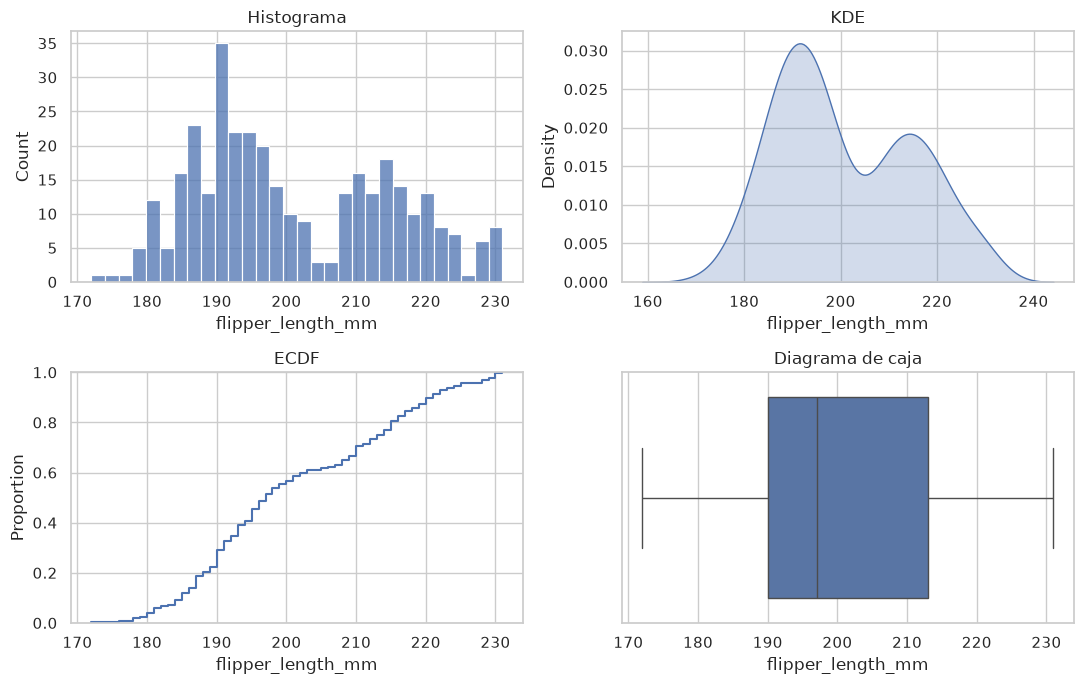

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
sns.histplot(pinguinos, x="flipper_length_mm", bins=30, ax=axes[0, 0]).set(title="Histograma")
sns.kdeplot(pinguinos, x="flipper_length_mm", fill=True, ax=axes[0, 1]).set(title="KDE")
sns.ecdfplot(pinguinos, x="flipper_length_mm", ax=axes[1, 0]).set(title="ECDF")
sns.boxplot(pinguinos, x="flipper_length_mm", ax=axes[1, 1]).set(title="Diagrama de caja")
plt.tight_layout()
plt.show()

**Interpretación:** el histograma y la KDE muestran **dos picos** (alrededor de 190 mm y de 210 a 215 mm), y la ECDF tiene un tramo casi plano entre ellos. El diagrama de caja, en cambio, **no delata nada**: no marca atípicos y nada en él sugiere dos picos. Tampoco es una caja simétrica: la mediana (197 mm) queda más cerca del primer cuartil (190 mm) que del tercero (213 mm), pero eso no basta para adivinar los dos picos. Es el ejemplo de por qué no basta con una gráfica: el diagrama de caja esconde la bimodalidad, así que nunca conviene describir una variable solo con él.

### Ejercicio 1 · ¿Por qué la aleta tiene dos picos y la masa no?

**🎯 Objetivo:** explicar una forma de la distribución con una variable de grupo. **Qué se espera aprender:** que la multimodalidad suele indicar una mezcla de poblaciones, y que una mezcla no siempre se ve como dos picos.

Grafica la distribución de `flipper_length_mm` y de `body_mass_g` **separada por especie** (pista: `sns.histplot(..., hue="species")` o `sns.kdeplot(..., hue="species")`). Explica por qué la distribución global de la aleta tiene **dos picos**, mientras que la de la masa tiene **un solo pico con un "hombro"** a la derecha, y qué cambia al separar por especie.

* La siguiente celda muestra una solución posible.

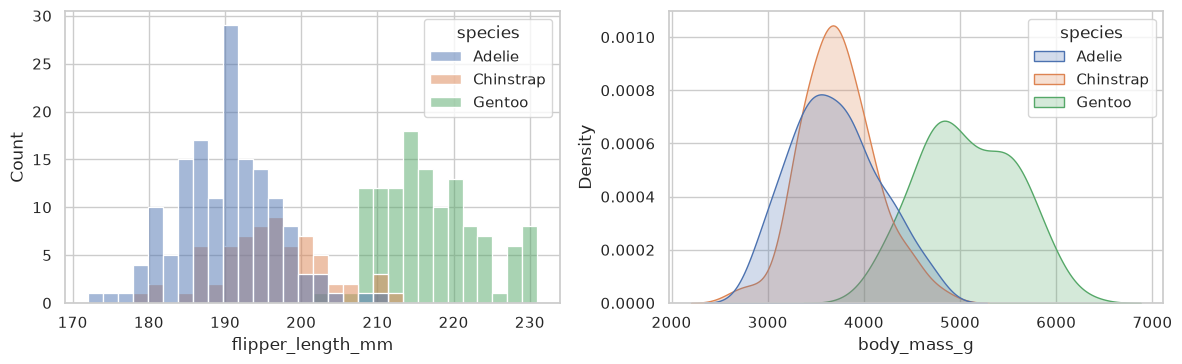

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(pinguinos, x="flipper_length_mm", hue="species", bins=30, ax=axes[0])
sns.kdeplot(pinguinos, x="body_mass_g", hue="species", fill=True, common_norm=False, ax=axes[1])
plt.tight_layout()
plt.show()

**✅ Respuesta sugerida:**

Los Gentoo forman un grupo propio (aletas de unos 217 mm y masas de unos 5,000 g), mientras que Adelie y Chinstrap se traslapan (aletas de 190 a 196 mm y masas de unos 3,700 g). En la **aleta**, los dos grupos están tan separados que la mezcla forma **dos picos** (lo mismo pasa con el largo del pico). En la **masa**, los Gentoo se traslapan más con las otras especies, así que la mezcla forma **un solo pico**, cerca de 3,700 g, con un **"hombro"** hacia los 5,000 g: hay mezcla de grupos aunque no se vean dos picos. Al separar por especie, cada distribución tiene un solo pico y es aproximadamente simétrica.

### Ejercicio 2 · Forma por especie.

**🎯 Objetivo:** comparar la forma de la distribución entre grupos. **Qué se espera aprender:** a calcular asimetría y curtosis por grupo y a decidir qué medidas reportar.

1. Calcula la asimetría y la curtosis de `body_mass_g` **por especie** y compara la media con la mediana en cada una.
2. Dibuja la ECDF de `body_mass_g` por especie. Con la gráfica, estima qué proporción de Gentoo pesa menos de 5,000 g y compruébalo con código.

* La siguiente celda muestra una solución posible.

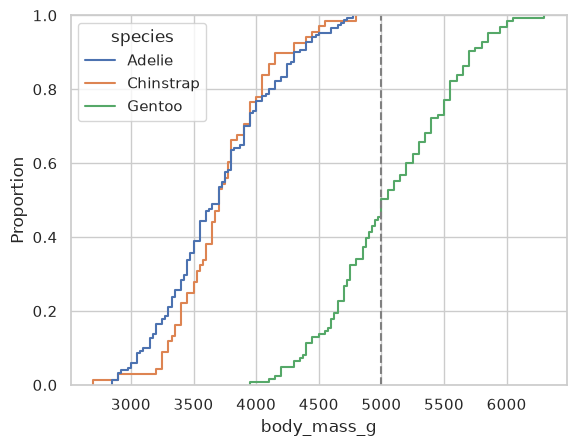

(           asimetria  curtosis    media  mediana
 species                                         
 Adelie          0.29     -0.57  3700.66   3700.0
 Chinstrap       0.25      0.59  3733.09   3700.0
 Gentoo          0.07     -0.72  5076.02   5000.0,
 0.455)

In [6]:
forma = pinguinos.groupby("species")["body_mass_g"].agg(
    asimetria="skew",
    curtosis=lambda s: s.kurt(),
    media="mean",
    mediana="median",
).round(2)
gentoo_menos_5000 = (pinguinos.loc[pinguinos["species"] == "Gentoo", "body_mass_g"] < 5000).mean()
sns.ecdfplot(pinguinos, x="body_mass_g", hue="species")
plt.axvline(5000, color="gray", linestyle="--")
plt.show()
forma, round(float(gentoo_menos_5000), 3)

**✅ Respuesta sugerida:**

En las tres especies la asimetría es pequeña (0.07 a 0.29) y la media casi coincide con la mediana (diferencias menores a 80 g), así que media y desviación estándar son buenas descripciones dentro de cada especie. La curtosis va de −0.72 (Gentoo) a 0.59 (Chinstrap, colas algo más pesadas): la misma magnitud que en el conjunto global, así que no describe colas muy distintas de las de una campana. Y, como se dijo en la sección 1, una curtosis negativa no prueba que haya grupos mezclados: los Gentoo, una sola especie, tienen −0.72. En la ECDF se lee que cerca de 45% de los Gentoo pesa menos de 5,000 g (el cálculo da 45.5%).

### Reto 1 · ¿Cuántos picos? Depende de cómo se mire.

**🎯 Objetivo:** ver cómo los parámetros de una gráfica cambian lo que parece mostrar. **Qué se espera aprender:** a no sacar conclusiones de un solo número de *bins* o ancho de banda.

Dibuja la KDE global de `flipper_length_mm` con `bw_adjust` igual a 0.2, 1 y 3, y el histograma con 5, 20 y 60 *bins*. ¿Cuándo aparecen o desaparecen picos? ¿Qué recomendarías para no engañarte?

* La siguiente celda muestra una solución posible.

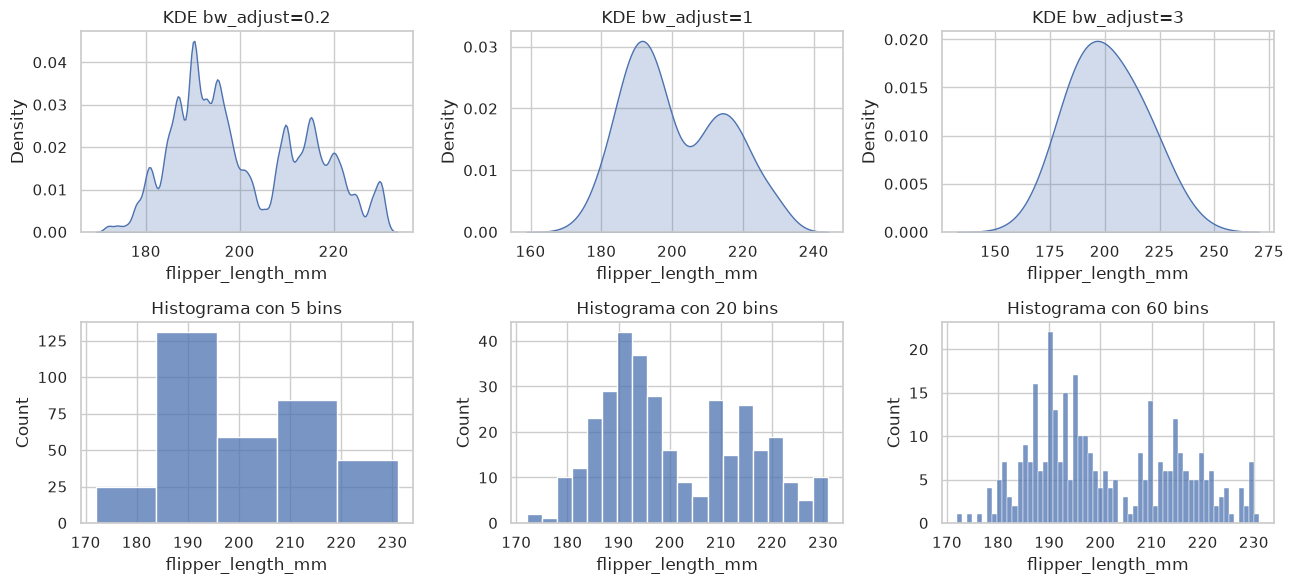

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, ajuste in zip(axes[0], [0.2, 1, 3]):
    sns.kdeplot(pinguinos, x="flipper_length_mm", bw_adjust=ajuste, fill=True, ax=ax).set(title=f"KDE bw_adjust={ajuste}")
for ax, n_bins in zip(axes[1], [5, 20, 60]):
    sns.histplot(pinguinos, x="flipper_length_mm", bins=n_bins, ax=ax).set(title=f"Histograma con {n_bins} bins")
plt.tight_layout()
plt.show()

**✅ Respuesta sugerida:**

Con `bw_adjust=0.2` o 60 *bins* aparecen picos espurios (ruido); con `bw_adjust=3` o 5 *bins* la bimodalidad casi desaparece. Conviene probar varios valores, complementar con la ECDF (que no tiene parámetros) y, sobre todo, buscar la explicación de los picos en otra variable (aquí, la especie).

📖 **Para profundizar (opcional).** *Fórmulas de la asimetría y la curtosis (sección 1).* La asimetría es $g_1 = \frac{1}{n}\sum (x_i - \bar{x})^3 / s^3$ y la curtosis en exceso, $g_2 = \frac{1}{n}\sum (x_i - \bar{x})^4 / s^4 - 3$ (*pandas* aplica además una corrección para muestras pequeñas). Elevar al cubo conserva el signo de las desviaciones, por eso la asimetría distingue la cola de la izquierda de la de la derecha; elevar a la cuarta da mucho peso a los valores lejanos, por eso la curtosis habla de las colas.

**💡 Ideas clave de la sección 1:**
* Asimetría (dirección de la cola), curtosis (peso de las colas) y número de picos describen la forma.
* Ninguna gráfica basta sola: el diagrama de caja oculta la multimodalidad; el histograma depende de los *bins*.
* La bimodalidad suele indicar grupos mezclados.

---
## ✅ Cierre.

**Práctica (en Classroom):** terminar los ejercicios pendientes de este *notebook* y, si es posible, un reto.

**Siguiente *notebook*:** `12_valores_atipicos_y_transformaciones.ipynb`.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>